TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


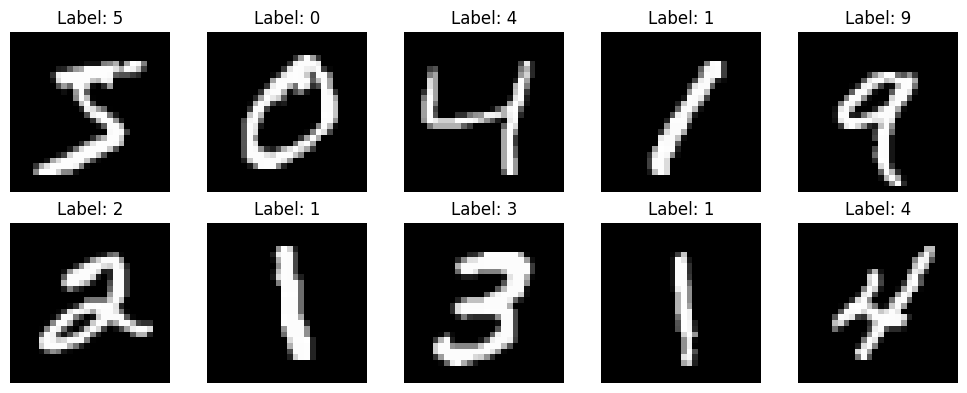

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 67ms/step - accuracy: 0.9210 - loss: 0.2636 - val_accuracy: 0.9822 - val_loss: 0.0674
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 74ms/step - accuracy: 0.9770 - loss: 0.0734 - val_accuracy: 0.9875 - val_loss: 0.0433
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - accuracy: 0.9836 - loss: 0.0537 - val_accuracy: 0.9882 - val_loss: 0.0430
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 64ms/step - accuracy: 0.9871 - loss: 0.0410 - val_accuracy: 0.9883 - val_loss: 0.0384
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - accuracy: 0.9889 - loss: 0.0362 - val_accuracy: 0.9910 - val_loss: 0.0352
Test Loss: 0.0269
Test Accuracy: 99.16 %


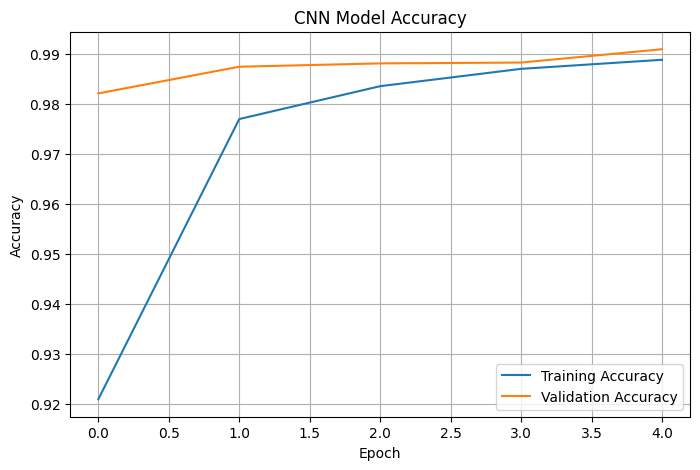

Predicted: 7 | Actual: 7


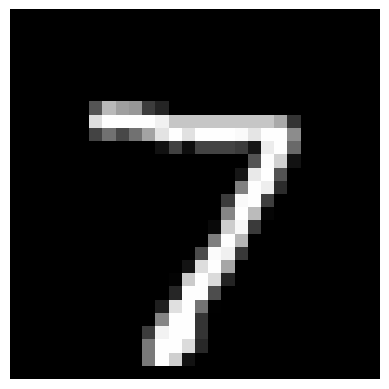

Model saved successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://07cd68b54e816c4b0c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [1]:
# Handwritten Digit Recognition Using CNN (full code in one cell)

!pip -q install gradio

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import gradio as gr
from PIL import Image, ImageOps

print("TensorFlow version:", tf.__version__)

# ---------- Load and preprocess data ----------
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# ---------- Build the CNN ----------
model = Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

# ---------- Train ----------
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# ---------- Evaluate ----------
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# ---------- Test one image ----------
index = 0
image = X_test[index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)
print("Predicted:", np.argmax(prediction[0]), "| Actual:", y_test[index])

plt.imshow(image.squeeze(), cmap="gray")
plt.axis("off")
plt.show()

# ---------- Save the model ----------
model.save("handwritten_digit_model.keras")
print("Model saved successfully!")

# ---------- Web interface ----------
def predict_digit(image):
    if image is None:
        return {"No image provided": 1.0}

    # Drawing canvas returns a dictionary; take the final drawing
    if isinstance(image, dict):
        image = image.get("composite")
        if image is None:
            return {"No image provided": 1.0}

    # Convert NumPy arrays to a PIL image
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image.astype("uint8"))

    # Put any transparency on a white background
    if image.mode in ("RGBA", "LA"):
        background = Image.new("RGB", image.size, (255, 255, 255))
        background.paste(image, mask=image.split()[-1])
        image = background

    image = ImageOps.grayscale(image).resize((28, 28))
    image_array = np.array(image).astype("float32")

    # MNIST digits are bright on dark, so invert bright images
    if image_array.mean() > 127:
        image_array = 255 - image_array

    image_array = (image_array / 255.0).reshape(1, 28, 28, 1)
    probabilities = model.predict(image_array, verbose=0)[0]
    return {str(d): float(probabilities[d]) for d in range(10)}

upload_demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(type="pil", label="Upload a handwritten digit image"),
    outputs=gr.Label(num_top_classes=3, label="Predictions"),
    title="Handwritten Digit Recognition Using CNN",
    description="Upload an image containing a single handwritten digit from 0 to 9."
)

draw_demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Sketchpad(label="Draw a digit (0-9)"),
    outputs=gr.Label(num_top_classes=3, label="Predictions"),
    title="Draw a Digit",
    description="Draw a single digit with a thick brush."
)

demo = gr.TabbedInterface([upload_demo, draw_demo], ["Upload", "Draw"])
demo.launch(share=True)